# Short-Horizon Reversal Strategy for Tesla

The reversal strategy completed 128 buy and 128 sell transactions. The sum of transaction cost rates was 0.128 under the 5 bps scenario and 0.256 under the 10 bps scenario.
The mean-reversion strategy generated positive returns but significantly underperformed buy-and-hold. Although it reduced volatility and maximum drawdown, its Sharpe ratio was also lower, indicating weaker risk-adjusted performance.
Overall, the results support the discussion in the lesson: short-horizon mean-reversion does not always perform well on individual stocks, especially when strong trends are present. 


In [27]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

print("Libraries imported successfully!")


Libraries imported successfully!


In [28]:

ticker = "TSLA"

data = yf.download(
    ticker,
    start="2011-01-01",
    end="2026-11-13",
    auto_adjust=True,
    progress=False
)

print("Dataset shape:", data.shape)
display(data.head())
display(data.tail())


Dataset shape: (3990, 5)


Price,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,
2011-01-03,1.774667,1.800000,1.726667,1.789333,19245000
2011-01-04,1.778000,1.796667,1.734667,1.777333,17811000
2011-01-05,1.788667,1.793333,1.746000,1.765333,21700500
2011-01-06,1.858667,1.866667,1.787333,1.788667,30918000
2011-01-07,1.882667,1.905333,1.860000,1.866667,33718500


Price,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,
2026-11-06,358.220001,363.839996,347.600006,348.920013,36730400
2026-11-09,378.049988,382.200012,360.019989,360.250000,36341400
2026-11-10,379.779999,380.000000,370.399994,370.850006,23999800
2026-11-11,390.839996,395.429993,386.350006,386.579987,27872700
2026-11-12,397.450012,401.220001,385.200012,386.359985,28925100


In [29]:

# Extract Tesla's adjusted closing prices
prices = data["Close"]["TSLA"].copy()

# Define the lookback window
N = 20

# Calculate the moving average and standard deviation
sma = prices.rolling(window=N).mean()
std = prices.rolling(window=N).std()

# Calculate the z-score
z_score = (prices - sma) / std

# Create a DataFrame for our strategy
df = pd.DataFrame({
    "Price": prices,
    "SMA_20": sma,
    "STD_20": std,
    "Z_Score": z_score
})

display(df.tail(10))


,Price,SMA_20,STD_20,Z_Score
Date,,,,
2026-10-30,399.809998,380.697499,14.314633,1.335172
2026-11-02,403.820007,381.951999,15.204863,1.438225
2026-11-03,398.500000,382.842999,15.642234,1.000944
2026-11-04,385.190002,383.212000,15.604258,0.126760
2026-11-05,343.690002,381.646500,17.876624,-2.123248
2026-11-06,358.220001,380.422499,18.623171,-1.192198
2026-11-09,378.049988,380.423499,18.623036,-0.127450
2026-11-10,379.779999,380.650998,18.584003,-0.046868
2026-11-11,390.839996,381.834998,18.432966,0.488527


In [30]:

# Create trading signals based on the z-score
position = 0
positions = []

for z in df["Z_Score"]:

    if pd.isna(z):
        position = 0

    elif position == 0 and z < -1:
        position = 1

    elif position == 1 and z >= 0:
        position = 0

    positions.append(position)

# Store the signal-based positions
df["Signal_Position"] = positions

# Apply the position on the next trading day
df["Position"] = df["Signal_Position"].shift(1).fillna(0).astype(int)

# Display recent signals and positions
display(
    df[["Price", "Z_Score", "Signal_Position", "Position"]].tail(15).round(3)
)


,Price,Z_Score,Signal_Position,Position
Date,,,,
2026-10-23,372.22,0.225,0,0
2026-10-26,391.62,1.807,0,0
2026-10-27,407.46,2.585,0,0
2026-10-28,404.22,2.017,0,0
2026-10-29,403.30,1.751,0,0
2026-10-30,399.81,1.335,0,0
2026-11-02,403.82,1.438,0,0
2026-11-03,398.50,1.001,0,0
2026-11-04,385.19,0.127,0,0


In [31]:

# Daily returns and transaction costs

df["Open"] = data["Open"]["TSLA"]

# Buy-and-hold daily returns
df["Daily_Return"] = df["Price"].pct_change().fillna(0)
df["Buy_Hold_Return"] = df["Daily_Return"]

# Position before and after today's opening trade
df["Previous_Position"] = df["Position"].shift(1).fillna(0)

# Returns before today's market open
df["Overnight_Return"] = (
    df["Open"] / df["Price"].shift(1) - 1
).fillna(0)

# Returns after today's market open
df["Intraday_Return"] = (
    df["Price"] / df["Open"] - 1
).fillna(0)

# Calculate gross strategy returns
df["Gross_Return"] = (
    (1 + df["Previous_Position"] * df["Overnight_Return"]) *
    (1 + df["Position"] * df["Intraday_Return"]) - 1
)

# Identify trades
df["Trade"] = df["Position"].diff().abs()
df["Trade"] = df["Trade"].fillna(df["Position"].abs())

# Transaction costs per side
cost_5bps = 0.0005
cost_10bps = 0.0010


# Initial buy-and-hold purchase at the first closing price
df.loc[df.index[0], "Buy_Hold_Return"] = -cost_5bps

# Net strategy returns
df["Net_Return_5bps"] = (
    df["Gross_Return"] - df["Trade"] * cost_5bps
)

df["Net_Return_10bps"] = (
    df["Gross_Return"] - df["Trade"] * cost_10bps
)

display(
    df[[
        "Open", "Price", "Position", "Trade",
        "Gross_Return", "Net_Return_5bps",
        "Net_Return_10bps"
    ]].tail(10).round(5)
)



,Open,Price,Position,Trade,Gross_Return,Net_Return_5bps,Net_Return_10bps
Date,,,,,,,
2026-10-30,393.22000,399.81000,0,0.0,0.00000,0.00000,0.00000
2026-11-02,404.66000,403.82001,0,0.0,0.00000,0.00000,0.00000
2026-11-03,406.25000,398.50000,0,0.0,0.00000,0.00000,0.00000
2026-11-04,379.79999,385.19000,0,0.0,0.00000,0.00000,0.00000
2026-11-05,374.12000,343.69000,0,0.0,0.00000,0.00000,0.00000
2026-11-06,348.92001,358.22000,1,1.0,0.02665,0.02615,0.02565
2026-11-09,360.25000,378.04999,1,0.0,0.05536,0.05536,0.05536
2026-11-10,370.85001,379.78000,1,0.0,0.00458,0.00458,0.00458
2026-11-11,386.57999,390.84000,1,0.0,0.02912,0.02912,0.02912


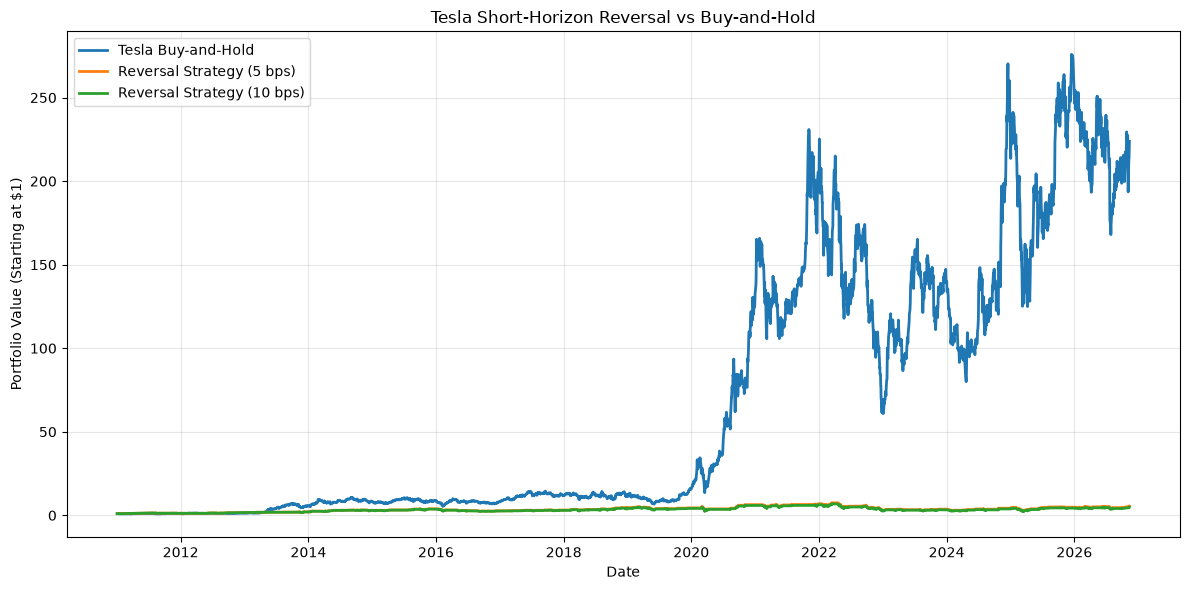

,Equity_Buy_Hold,Equity_5bps,Equity_10bps
Date,,,
2026-11-12,223.846,5.594,4.923


In [32]:

# Calculate cumulative equity curves
df["Equity_Buy_Hold"] = (1 + df["Buy_Hold_Return"]).cumprod()

df["Equity_5bps"] = (1 + df["Net_Return_5bps"]).cumprod()

df["Equity_10bps"] = (1 + df["Net_Return_10bps"]).cumprod()

# Plot the equity curves
plt.figure(figsize=(12, 6))

plt.plot(
    df.index, df["Equity_Buy_Hold"],
    label="Tesla Buy-and-Hold", linewidth=2
)

plt.plot(
    df.index, df["Equity_5bps"],
    label="Reversal Strategy (5 bps)", linewidth=2
)

plt.plot(
    df.index, df["Equity_10bps"],
    label="Reversal Strategy (10 bps)", linewidth=2
)

plt.title("Tesla Short-Horizon Reversal vs Buy-and-Hold")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (Starting at $1)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display final portfolio values
display(
    df[[
        "Equity_Buy_Hold",
        "Equity_5bps",
        "Equity_10bps"
    ]].tail(1).round(3)
)


In [33]:

# Define annual trading days and risk-free rate
trading_days = 252
risk_free_rate = 0.0

# Function to calculate performance statistics
def performance_metrics(returns):

    equity = (1 + returns).cumprod()

    annual_return = equity.iloc[-1] ** (
        trading_days / len(returns)
    ) - 1

    annual_volatility = returns.std() * np.sqrt(trading_days)

    annual_mean_return = returns.mean() * trading_days

    sharpe = (
        (annual_mean_return - risk_free_rate) / annual_volatility
        if annual_volatility > 0 else np.nan
    )

    running_max = equity.cummax()
    drawdown = equity / running_max - 1
    max_drawdown = drawdown.min()

    return {
        "Annualised Return": annual_return,
        "Annualised Volatility": annual_volatility,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": max_drawdown
    }

# Compare performance
results = pd.DataFrame({
    "Buy-and-Hold": performance_metrics(df["Buy_Hold_Return"]),
    "Reversal (5 bps)": performance_metrics(df["Net_Return_5bps"]),
    "Reversal (10 bps)": performance_metrics(df["Net_Return_10bps"])
}).T

# Trading activity and total transaction costs
number_of_trades = int(df["Trade"].sum())

total_cost_5bps = df["Trade"].sum() * cost_5bps
total_cost_10bps = df["Trade"].sum() * cost_10bps

results["Number of Trades"] = [
    1,
    number_of_trades,
    number_of_trades
]

results["Total Trading Cost"] = [
    cost_5bps,
    total_cost_5bps,
    total_cost_10bps
]

display(results.round(4))


,Annualised Return,Annualised Volatility,Sharpe Ratio,Maximum Drawdown,Number of Trades,Total Trading Cost
Buy-and-Hold,0.4074,0.5667,0.8850,-0.7363,1,0.0005
Reversal (5 bps),0.1149,0.3563,0.4820,-0.6624,256,0.1280
Reversal (10 bps),0.1059,0.3562,0.4594,-0.6691,256,0.2560


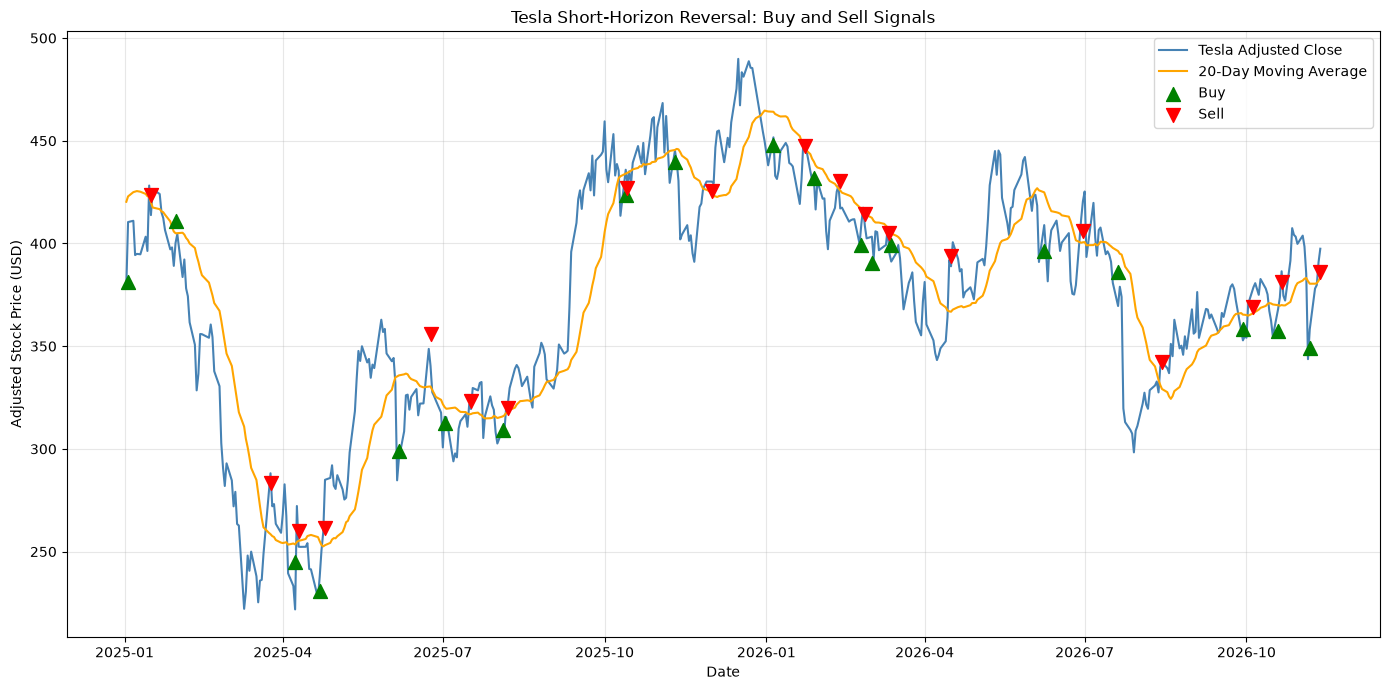

In [34]:

# Identify actual buy and sell dates
df["Buy_Signal"] = (df["Position"] == 1) & (df["Position"].shift(1) == 0)
df["Sell_Signal"] = (df["Position"] == 0) & (df["Position"].shift(1) == 1)

# Focus on the last two years for better visibility
plot_data = df.loc["2025-01-01":].copy()

# Plot Tesla's price and moving average
plt.figure(figsize=(14, 7))

plt.plot(
    plot_data.index,
    plot_data["Price"],
    label="Tesla Adjusted Close",
    color="steelblue",
    linewidth=1.5
)

plt.plot(
    plot_data.index,
    plot_data["SMA_20"],
    label="20-Day Moving Average",
    color="orange",
    linewidth=1.5
)

# Mark buy dates
plt.scatter(
    plot_data.index[plot_data["Buy_Signal"]],
    plot_data.loc[plot_data["Buy_Signal"], "Open"],
    marker="^",
    color="green",
    s=100,
    label="Buy",
    zorder=5
)

# Mark sell dates
plt.scatter(
    plot_data.index[plot_data["Sell_Signal"]],
    plot_data.loc[plot_data["Sell_Signal"], "Open"],
    marker="v",
    color="red",
    s=100,
    label="Sell",
    zorder=5
)

plt.title("Tesla Short-Horizon Reversal: Buy and Sell Signals")
plt.xlabel("Date")
plt.ylabel("Adjusted Stock Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [35]:

# Final backtest validation

print("Total observations:", len(df))
print("First date:", df.index.min().date())
print("Last date:", df.index.max().date())

print("\nTrading activity:")
print("Buy orders:", int(df["Buy_Signal"].sum()))
print("Sell orders:", int(df["Sell_Signal"].sum()))
print("Total trading sides:", int(df["Trade"].sum()))

print("\nTransaction costs (sum of daily cost rates):")
print("5 bps:", round((df["Trade"] * cost_5bps).sum(), 4))
print("10 bps:", round((df["Trade"] * cost_10bps).sum(), 4))

print("\nPosition values:", df["Position"].unique())

# Check that all positions use the previous day's signal
assert (
    df["Position"] ==
    df["Signal_Position"].shift(1).fillna(0)
).all()

print("\nPosition timing check passed!")


Total observations: 3990
First date: 2011-01-03
Last date: 2026-11-12

Trading activity:
Buy orders: 128
Sell orders: 128
Total trading sides: 256

Transaction costs (sum of daily cost rates):
5 bps: 0.128
10 bps: 0.256

Position values: [0 1]

Position timing check passed!
